# Quick-Commerce Delivery Intelligence — Manthan Hackathon

## 1. Project Overview

This notebook completes PS2 (Delay Lens) and PS3 (descriptive EDA) only. It reads completed PS1 outputs, preserves every record, and creates reusable CSV, JSON, and PNG artifacts for future Streamlit pages. A 30-minute analytical threshold is used; it is not an officially confirmed customer promise. Late labels are generated only for records with valid delivery-time targets. No model is trained and PS4–PS8 are out of scope.

**Dataset applicability:** the available data represents food-delivery operations, while the hackathon focuses on quick-commerce. Interpret results as evidence from this dataset; they may not generalize to grocery or instant-commerce without validation on actual quick-commerce operations.

## Dataset Limitations and Applicability

The available dataset represents food-delivery operations, while this hackathon concerns quick-commerce delivery intelligence. Food and grocery/instant-commerce orders can differ in assortment, picking, batching, fulfillment, and service expectations. Therefore, findings in this notebook describe the available delivery dataset and should not automatically be generalized to all quick-commerce businesses. Actual quick-commerce operational data is required for stronger validation.

## 2. Project Structure and Configuration

All paths are project-relative. `SLA_MINUTES = 30` is the primary analytical threshold selected for this analysis; it is not an officially confirmed customer delivery promise.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', context='notebook')
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p/'data'/'final_cleaned_data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find data/final_cleaned_data.csv relative to notebook.')
DATA = ROOT/'data'
OUT = ROOT/'outputs'
PS2 = OUT/'ps2'
EDA = OUT/'eda'
FINAL_PATH = DATA/'final_cleaned_data.csv'
SOURCE_PATH = DATA/'train.csv'
MODEL_PATH = DATA/'model_ready_data.csv'
SLA_MINUTES = 30
SLA_STATUS = 'analytical_threshold_not_official_sla'
SLA_OFFICIAL_CONFIRMATION = False
DATASET_LIMITATION = ('This dataset represents food-delivery operations; results may not generalize to quick-commerce. '
                     'Actual quick-commerce operational data is required for stronger validation.')
RIDER_EXPERIENCE_AVAILABLE = any(name in pd.read_csv(FINAL_PATH, nrows=0).columns
                                 for name in ['Rider_Experience_Years', 'Delivery_person_Experience', 'rider_tenure_years'])
PS2.mkdir(parents=True, exist_ok=True)
EDA.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

PS1_HASH = sha256(FINAL_PATH)
SOURCE_HASH = sha256(SOURCE_PATH)

## 3. Dataset Loading

Load the existing PS1 final data and source copy for observed-value provenance. Both are read-only; snapshot PS1 in memory so final validation can confirm it did not change.

In [2]:
if not SOURCE_PATH.is_file():
    raise FileNotFoundError(SOURCE_PATH)
try:
    data = pd.read_csv(FINAL_PATH)
    source = pd.read_csv(SOURCE_PATH, dtype='string', keep_default_na=False)
except (OSError, pd.errors.ParserError, UnicodeError) as exc:
    raise RuntimeError(f'Could not load project data: {exc}') from exc
ps1_snapshot = data.copy(deep=True)
rows_before = len(data)
source_rows = len(source)
print('PS1 shape:', data.shape, '| source rows:', source_rows)
print('Exact duplicate rows:', int(data.duplicated().sum()))
print('Unique order IDs:', data.ID.astype('string').str.strip().nunique())
display(data.head())

PS1 shape: (45593, 50) | source rows: 45593
Exact duplicate rows: 0
Unique order IDs: 45593


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),Delivery_person_Age_original,Delivery_person_Age_invalid,Delivery_person_Age_unparseable,restaurant_gps_invalid,delivery_gps_invalid,gps_invalid_any,gps_geographic_eligible,Order_Date_missing,Time_Orderd_missing,Time_Order_picked_missing,Vehicle_condition_original,Vehicle_condition_invalid,restaurant_gps_missing,restaurant_gps_zero,restaurant_gps_placeholder,restaurant_gps_out_of_global_range,restaurant_gps_outside_india,restaurant_gps_valid,restaurant_source_zero_placeholder,delivery_gps_missing,delivery_gps_zero,delivery_gps_placeholder,delivery_gps_out_of_global_range,delivery_gps_outside_india,delivery_gps_valid,delivery_source_zero_placeholder,gps_missing_any,gps_zero_or_placeholder_source,Distance_km,distance_unusual_iqr
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,2.0,Snack,motorcycle,0.0,No,Urban,24,37,False,False,False,False,False,True,False,False,False,2,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,3.025153,False
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,2.0,Snack,scooter,1.0,No,Metropolitan,33,34,False,False,False,False,False,True,False,False,False,2,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,20.183558,False
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,0.0,Drinks,motorcycle,1.0,No,Urban,26,23,False,False,False,False,False,True,False,False,False,0,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,1.552760,False
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,0.0,Buffet,motorcycle,1.0,No,Metropolitan,21,38,False,False,False,False,False,True,False,False,False,0,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,7.790412,False
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,1.0,Snack,scooter,1.0,No,Metropolitan,30,32,False,False,False,False,False,True,False,False,False,1,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,6.210147,False


## 4. Dataset Understanding

Check actual columns, dtypes, missingness, categories, target, time fields, and PS1 GPS flags before analysis.

In [3]:
REQUIRED = ['ID','Delivery_person_Age','Delivery_person_Ratings','Restaurant_latitude','Restaurant_longitude',
 'Delivery_location_latitude','Delivery_location_longitude','Order_Date','Time_Orderd','Time_Order_picked',
 'Weatherconditions','Road_traffic_density','Vehicle_condition','Type_of_order','Type_of_vehicle',
 'multiple_deliveries','Festival','City','Time_taken(min)','gps_invalid_any',
 'gps_geographic_eligible','Distance_km']
missing_columns = sorted(set(REQUIRED)-set(data.columns))
if missing_columns:
    raise KeyError(f'Missing expected PS1 columns: {missing_columns}')
schema = pd.DataFrame({'dtype':data.dtypes.astype(str),'missing':data.isna().sum(),
                       'missing_percent':(100*data.isna().mean()).round(2),
                       'unique':data.nunique(dropna=True)})
display(schema)
for col in ['Weatherconditions','Road_traffic_density','Vehicle_condition','Type_of_order',
            'Type_of_vehicle','multiple_deliveries','Festival','City','gps_geographic_eligible']:
    print(f'\\n{col} value counts:')
    display(data[col].value_counts(dropna=False).rename_axis(col).to_frame('records'))

,dtype,missing,missing_percent,unique
ID,str,0,0.00,45593
Delivery_person_ID,str,0,0.00,1320
Delivery_person_Age,float64,0,0.00,21
Delivery_person_Ratings,float64,0,0.00,27
Restaurant_latitude,float64,3640,7.98,656
Restaurant_longitude,float64,3640,7.98,517
Delivery_location_latitude,float64,3640,7.98,4362
Delivery_location_longitude,float64,3640,7.98,4362
Order_Date,str,0,0.00,44
Time_Orderd,str,1731,3.80,176


\nWeatherconditions value counts:


,records
Weatherconditions,
Fog,7654
Stormy,7586
Cloudy,7536
Sandstorms,7495
Windy,7422
Sunny,7284
Unknown,616


\nRoad_traffic_density value counts:


,records
Road_traffic_density,
Low,15477
Jam,14143
Medium,10947
High,4425
Unknown,601


\nVehicle_condition value counts:


... (9 outputs left out)

\nCity value counts:


,records
City,
Metropolitan,34093
Urban,10136
Unknown,1200
Semi-Urban,164


\ngps_geographic_eligible value counts:


,records
gps_geographic_eligible,
True,41522
False,4071


## 5. PS2 – Delivery Time Definition

`Time_taken(min)` records the order's actual end-to-end delivery duration in minutes. Preserve it and create a numeric `delivery_time` alias; missing target values are never imputed.

In [4]:
TARGET_SOURCE = 'Time_taken(min)'
original_target = pd.to_numeric(data[TARGET_SOURCE], errors='coerce').copy()
delivery_time = original_target.rename('delivery_time')
if not np.array_equal(delivery_time.to_numpy(float), data[TARGET_SOURCE].to_numpy(float)):
    raise AssertionError('Numeric target alias differs from the original target.')
display(delivery_time.describe().rename('delivery_time_minutes').to_frame())
print('Valid / missing targets:', int(delivery_time.notna().sum()), int(delivery_time.isna().sum()))

,delivery_time_minutes
count,45593.000000
mean,26.294607
std,9.383806
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


Valid / missing targets: 45593 0


## 6. PS2 ? SLA Configuration

Since the official SLA was not specified in the available hackathon requirements, a 30-minute analytical SLA was selected based on the delivery-time distribution. It is used for analytical modelling and operational insights, not as an officially guaranteed delivery promise. The 30-minute choice is configurable and is not represented as an official customer commitment.

In [5]:
if SLA_MINUTES != 30 or SLA_STATUS != 'analytical_threshold_not_official_sla':
    raise AssertionError('The primary threshold/status must remain the 30-minute analytical setting.')
print('SLA_MINUTES =', SLA_MINUTES, '| status =', SLA_STATUS)

SLA_MINUTES = 30 | status = analytical_threshold_not_official_sla


## 7. PS2 ? Late Delivery Target

Keep `Time_taken(min)` unchanged and store its numeric value in `delivery_time`. Under the selected 30-minute analytical threshold, delivery time <= 30 is on time (0) and delivery time > 30 is late (1). Missing targets stay missing and are excluded from the percentage denominator; they are never assigned on-time. These labels support analysis only, not a confirmed delivery promise.

In [6]:
prepared = data.copy(deep=True)
prepared['delivery_time'] = delivery_time
valid_target_mask = prepared['delivery_time'].notna()
prepared['is_late'] = pd.Series(pd.NA, index=prepared.index, dtype='Int64')
prepared.loc[valid_target_mask, 'is_late'] = (
    prepared.loc[valid_target_mask, 'delivery_time'].gt(SLA_MINUTES).astype('int64').astype('Int64')
)
labels = prepared.loc[valid_target_mask, 'is_late']
if not labels.isin([0, 1]).all():
    raise AssertionError('Non-missing late labels must be binary.')
late_count = int(labels.eq(1).sum())
on_time_count = int(labels.eq(0).sum())
valid_target_count = int(valid_target_mask.sum())
late_percent = float(late_count / valid_target_count * 100) if valid_target_count else None
on_time_percent = float(on_time_count / valid_target_count * 100) if valid_target_count else None
class_distribution = pd.DataFrame([
    {'class': 'On time (<= 30 minutes)', 'is_late': 0, 'records': on_time_count, 'percent_of_valid_targets': on_time_percent},
    {'class': 'Late (> 30 minutes)', 'is_late': 1, 'records': late_count, 'percent_of_valid_targets': late_percent},
])
print('Class distribution (valid delivery-time targets only):')
display(class_distribution)
print(f'On time: {on_time_count:,} ({on_time_percent:.2f}%)')
print(f'Late: {late_count:,} ({late_percent:.2f}%)')
print(f'Missing targets retained as missing: {int(prepared["delivery_time"].isna().sum()):,}')

SENSITIVITY_THRESHOLDS = [28, 30, 32, 35]
sensitivity_rows = []
for threshold in SENSITIVITY_THRESHOLDS:
    late_at_threshold = int(prepared.loc[valid_target_mask, 'delivery_time'].gt(threshold).sum())
    sensitivity_rows.append({
        'sla_minutes': threshold,
        'late_count': late_at_threshold,
        'on_time_count': valid_target_count - late_at_threshold,
        'valid_target_count': valid_target_count,
        'late_percent': late_at_threshold / valid_target_count * 100 if valid_target_count else np.nan,
        'on_time_percent': (valid_target_count - late_at_threshold) / valid_target_count * 100 if valid_target_count else np.nan,
        'primary_analytical_sla': threshold == SLA_MINUTES,
    })
sla_sensitivity = pd.DataFrame(sensitivity_rows)
print('Sensitivity analysis:')
display(sla_sensitivity)
assert int(sla_sensitivity.loc[sla_sensitivity.sla_minutes.eq(SLA_MINUTES), 'late_count'].iloc[0]) == late_count

Class distribution (valid delivery-time targets only):


,class,is_late,records,percent_of_valid_targets
0,On time (<= 30 minutes),0,31987,70.1577
1,Late (> 30 minutes),1,13606,29.8423


On time: 31,987 (70.16%)
Late: 13,606 (29.84%)
Missing targets retained as missing: 0
Sensitivity analysis:


,sla_minutes,late_count,on_time_count,valid_target_count,late_percent,on_time_percent,primary_analytical_sla
0,28,16780,28813,45593,36.803895,63.196105,False
1,30,13606,31987,45593,29.842300,70.157700,True
2,32,11269,34324,45593,24.716513,75.283487,False
3,35,8006,37587,45593,17.559713,82.440287,False


## 8. PS2 – Haversine Distance

Haversine estimates great-circle distance from latitude/longitude. Reuse PS1 eligibility flags, additionally validate global limits and broad India bounds, and reuse the existing PS1 distance after comparing it with an independent formula check. Invalid coordinates remain unmodified and have no distance.

In [7]:
lat1 = pd.to_numeric(data.Restaurant_latitude, errors='coerce')
lon1 = pd.to_numeric(data.Restaurant_longitude, errors='coerce')
lat2 = pd.to_numeric(data.Delivery_location_latitude, errors='coerce')
lon2 = pd.to_numeric(data.Delivery_location_longitude, errors='coerce')
coords = pd.concat([lat1,lon1,lat2,lon2],axis=1)
present = coords.notna().all(axis=1)
global_ok = lat1.between(-90,90)&lat2.between(-90,90)&lon1.between(-180,180)&lon2.between(-180,180)
india_ok = lat1.between(6.5,37.5)&lat2.between(6.5,37.5)&lon1.between(68,98)&lon2.between(68,98)
gps_valid = data.gps_geographic_eligible.fillna(False).astype(bool) & ~data.gps_invalid_any.fillna(True).astype(bool) & present & global_ok & india_ok
gps_invalid = ~gps_valid
computed = pd.Series(np.nan,index=data.index,dtype=float)
if gps_valid.any():
    a1,a2=np.radians(lat1[gps_valid]),np.radians(lat2[gps_valid])
    dl=np.radians(lat2[gps_valid]-lat1[gps_valid])
    dn=np.radians(lon2[gps_valid]-lon1[gps_valid])
    hav=np.sin(dl/2)**2+np.cos(a1)*np.cos(a2)*np.sin(dn/2)**2
    computed[gps_valid]=6371.0088*2*np.arcsin(np.sqrt(np.clip(hav,0,1)))
existing=pd.to_numeric(data.Distance_km,errors='coerce')
if existing[gps_valid].notna().all():
    if not np.allclose(existing[gps_valid],computed[gps_valid],rtol=1e-8,atol=1e-6):
        raise AssertionError('PS1 Distance_km failed independent Haversine check.')
    distance_km=existing.where(gps_valid)
    distance_method='Reused validated PS1 Distance_km'
else:
    distance_km=computed.where(gps_valid)
    distance_method='Calculated Haversine distance'
if distance_km[gps_invalid].notna().any():
    raise AssertionError('Invalid GPS rows received distance.')
dv=distance_km[gps_valid]
assert dv.notna().all() and np.isfinite(dv).all() and dv.ge(0).all()
if len(dv):
    q1,q3=dv.quantile([.25,.75]); distance_fence=float(q3+1.5*(q3-q1))
    unusual=distance_km.gt(distance_fence).fillna(False)
else:
    distance_fence=None; unusual=pd.Series(False,index=data.index)
prepared['distance_km']=distance_km
prepared=prepared.drop(columns=['Distance_km'])
prepared['distance_unusual_iqr']=unusual.astype(bool)
print('Method:',distance_method,'| valid/invalid:',int(gps_valid.sum()),int(gps_invalid.sum()))
print('Distance min/max km:',float(dv.min()),float(dv.max()),'| IQR fence:',distance_fence,'| unusual:',int(unusual.sum()))

Method: Reused validated PS1 Distance_km | valid/invalid: 41522 4071
Distance min/max km: 1.465069428868235 20.96951834437969 | IQR fence: 27.215855380149375 | unusual: 0


## 9. PS2 – Feature Availability

Only order date/time, order type, city, festival status, and valid-address distance are treated as placement-time candidates. These lists and the generated availability report are the single source of truth for future Module 03 inputs; the PS1 preprocessing illustration is not authoritative. Availability of `Order_Date`, `Time_Orderd`, `Type_of_order`, `City`, and `Festival` assumes each is captured or derivable at order submission. `distance_km` assumes the customer destination and selected restaurant/dark-store coordinates are known before the prediction is made; verify that store selection and location capture happen by that point in the operational workflow. Rider assignment fields are post-order. Weather and traffic capture timing is unverified and conservatively excluded.

In [8]:
ORDER_PLACEMENT_FEATURES=['Order_Date','Time_Orderd','Type_of_order','City','Festival','distance_km']
POST_ORDER_FEATURES=['Time_Order_picked','Delivery_person_ID','Delivery_person_Age','Delivery_person_Ratings',
 'Vehicle_condition','Vehicle_condition_original','Vehicle_condition_invalid','Type_of_vehicle','multiple_deliveries']
UNVERIFIED_FEATURES=['Weatherconditions','Road_traffic_density']
TARGET_COLUMNS=[TARGET_SOURCE,'delivery_time','is_late']
print('Order-placement candidates:',ORDER_PLACEMENT_FEATURES)
print('Post-order/assignment-dependent:',POST_ORDER_FEATURES)
print('Timing unverified, excluded:',UNVERIFIED_FEATURES)
print('Targets:',TARGET_COLUMNS)

Order-placement candidates: ['Order_Date', 'Time_Orderd', 'Type_of_order', 'City', 'Festival', 'distance_km']
Post-order/assignment-dependent: ['Time_Order_picked', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition', 'Vehicle_condition_original', 'Vehicle_condition_invalid', 'Type_of_vehicle', 'multiple_deliveries']
Timing unverified, excluded: ['Weatherconditions', 'Road_traffic_density']
Targets: ['Time_taken(min)', 'delivery_time', 'is_late']


## 10. PS2 – Data Leakage Prevention

Pickup timestamps, rider assignments, downstream dispatch facts, and target outcomes would not be available at order placement. Using them would make validation unrealistically optimistic. Both reusable feature lists contain only order-placement candidates.

In [9]:
REGRESSION_FEATURES=ORDER_PLACEMENT_FEATURES.copy()
CLASSIFICATION_FEATURES=ORDER_PLACEMENT_FEATURES.copy()
for features in [REGRESSION_FEATURES,CLASSIFICATION_FEATURES]:
    assert set(features)<=set(prepared.columns)
    assert not set(features)&set(TARGET_COLUMNS)
    assert not set(features)&set(POST_ORDER_FEATURES)
    assert not set(features)&set(UNVERIFIED_FEATURES)
assert 'Time_Order_picked' not in REGRESSION_FEATURES+CLASSIFICATION_FEATURES
availability=[]
AVAILABILITY_ASSUMPTIONS={
 'Order_Date':'Assumes the order calendar date is recorded at submission.',
 'Time_Orderd':'Assumes this is the order-submission time, not a later derived timestamp.',
 'Type_of_order':'Assumes the customer-selected order category is known at submission.',
 'City':'Assumes the destination city/service area is known from the order address at submission.',
 'Festival':'Assumes the date/location calendar flag is derivable before the order-placement prediction.',
 'distance_km':'Assumes the selected restaurant/dark store and customer destination coordinates are known before prediction; verify store-selection timing in the operational workflow.',
}
for col in prepared.columns:
    if col in ORDER_PLACEMENT_FEATURES: group,available,reason='A: placement candidate',True,AVAILABILITY_ASSUMPTIONS[col]
    elif col in POST_ORDER_FEATURES: group,available,reason='B: post-order',False,'Dispatch/rider/pickup information is not available at placement.'
    elif col in UNVERIFIED_FEATURES: group,available,reason='Timing unverified',None,'Conservatively excluded until capture timing is confirmed.'
    elif col in TARGET_COLUMNS: group,available,reason='C: target',False,'Outcome; never a model input.'
    elif col in [lat1.name,lon1.name,lat2.name,lon2.name]: group,available,reason='Location source',None,'Used only to validate distance; raw coordinates excluded as inputs.'
    else: group,available,reason='Identifier/quality/audit field',False,'Excluded to avoid leakage or use of audit metadata.'
    availability.append({'column':col,'group':group,'available_at_order_placement':available,
       'in_regression_features':col in REGRESSION_FEATURES,'in_classification_features':col in CLASSIFICATION_FEATURES,'reason':reason})
feature_report=pd.DataFrame(availability)
feature_report['availability_assumption']=feature_report['column'].map(AVAILABILITY_ASSUMPTIONS).fillna('Not used as an order-placement input.')
for flag_column,feature_list in [('in_regression_features',REGRESSION_FEATURES),('in_classification_features',CLASSIFICATION_FEATURES)]:
    reported=set(feature_report.loc[feature_report[flag_column], 'column'])
    assert reported==set(feature_list),f'{flag_column} report does not match the canonical feature list.'
    assert feature_report.loc[feature_report.column.isin(feature_list),'available_at_order_placement'].eq(True).all()
assert set(REGRESSION_FEATURES)==set(CLASSIFICATION_FEATURES)
assert not set(REGRESSION_FEATURES)&set(TARGET_COLUMNS+POST_ORDER_FEATURES+UNVERIFIED_FEATURES)
assert set(REGRESSION_FEATURES)<=set(prepared.columns)
display(feature_report[feature_report.group.isin(['A: placement candidate','B: post-order','Timing unverified','C: target'])])

,column,group,available_at_order_placement,in_regression_features,in_classification_features,reason,availability_assumption
1,Delivery_person_ID,B: post-order,False,False,False,Dispatch/rider/pickup information is not avail...,Not used as an order-placement input.
2,Delivery_person_Age,B: post-order,False,False,False,Dispatch/rider/pickup information is not avail...,Not used as an order-placement input.
3,Delivery_person_Ratings,B: post-order,False,False,False,Dispatch/rider/pickup information is not avail...,Not used as an order-placement input.
8,Order_Date,A: placement candidate,True,True,True,Assumes the order calendar date is recorded at...,Assumes the order calendar date is recorded at...
9,Time_Orderd,A: placement candidate,True,True,True,"Assumes this is the order-submission time, not...","Assumes this is the order-submission time, not..."
10,Time_Order_picked,B: post-order,False,False,False,Dispatch/rider/pickup information is not avail...,Not used as an order-placement input.
11,Weatherconditions,Timing unverified,None,False,False,Conservatively excluded until capture timing i...,Not used as an order-placement input.
12,Road_traffic_density,Timing unverified,None,False,False,Conservatively excluded until capture timing i...,Not used as an order-placement input.
13,Vehicle_condition,B: post-order,False,False,False,Dispatch/rider/pickup information is not avail...,Not used as an order-placement input.
14,Type_of_order,A: placement candidate,True,True,True,Assumes the customer-selected order category i...,Assumes the customer-selected order category i...


## 11. PS2 – Model-Ready Dataset

Retain all rows, including invalid-GPS orders for non-geographic use. Preserve the source target and include its numeric alias, nullable late label, and distance. No records are filtered.

In [10]:
model_ready=prepared.copy(deep=True)
assert len(model_ready)==rows_before
assert model_ready.columns.tolist().count('distance_km')==1 and 'Distance_km' not in model_ready.columns
assert model_ready.is_late.isna().all() if SLA_MINUTES is None else model_ready.is_late.dropna().isin([0,1]).all()
print('Shape:',model_ready.shape,'| retained:',len(model_ready),'| late labels:',int(model_ready.is_late.notna().sum()))
display(model_ready[['Time_taken(min)','delivery_time','is_late','distance_km','gps_geographic_eligible']].head())

Shape: (45593, 52) | retained: 45593 | late labels: 45593


,Time_taken(min),delivery_time,is_late,distance_km,gps_geographic_eligible
0,24,24,0,3.025153,True
1,33,33,1,20.183558,True
2,26,26,0,1.552760,True
3,21,21,0,7.790412,True
4,30,30,0,6.210147,True


## 12. PS2 – Validation and Output Saving

Write reusable data, a structured delay summary, feature availability, and validation status. The validation report records the pending SLA and explicitly shows that no rows were removed.

In [11]:
def metric(name,value,detail):
    return {'metric':name,'value':value,'detail':detail}
validation=pd.DataFrame([
 metric('source_records',source_rows,'Rows in read-only source.'),
 metric('ps1_records',rows_before,'Rows in completed PS1 dataset.'),
 metric('model_ready_records',len(model_ready),'Every record retained.'),
 metric('duplicate_rows',int(model_ready.duplicated().sum()),'Exact duplicate rows.'),
 metric('missing_delivery_targets',int(model_ready.delivery_time.isna().sum()),'Never imputed; exclude only from supervised target training.'),
 metric('sla_minutes',SLA_MINUTES,'30-minute analytical threshold; not an officially confirmed customer promise.'),
 metric('sla_status',SLA_STATUS,'Analytical label is generated; official SLA is unconfirmed.'),
 metric('late_records',late_count,'Delivery time strictly greater than 30 minutes.'),
 metric('on_time_records',on_time_count,'Delivery time less than or equal to 30 minutes.'),
 metric('valid_target_records',valid_target_count,'Denominator for class percentages; missing targets excluded.'),
 metric('late_percent',late_percent,'Percentage of valid delivery-time targets.'),
 metric('on_time_percent',on_time_percent,'Percentage of valid delivery-time targets.'),
 metric('gps_valid_records',int(gps_valid.sum()),'Valid coordinate pairs within checks.'),
 metric('gps_invalid_records',int(gps_invalid.sum()),'Retained for non-geographic analysis.'),
 metric('distance_success_records',int(dv.notna().sum()),'Finite, non-negative Haversine distances.'),
 metric('canonical_distance_column_count',int(model_ready.columns.tolist().count('distance_km')),'Exactly one canonical distance_km column is exported; redundant PS1 Distance_km alias is omitted.'),
 metric('unusual_distance_records',int(unusual.sum()),'Upper 1.5 IQR fence; retained.'),
 metric('rows_removed',0,'No rows removed.'),
 metric('age_validation_range','18-80','Age validation range applied consistently to Module 02 age summaries.'),
 metric('rider_experience_field_available',RIDER_EXPERIENCE_AVAILABLE,'No tenure/experience field found.'),
 metric('dataset_applicability',DATASET_LIMITATION,'Interpret findings within this food-delivery dataset.'),
])
summary={'dataset':{'source':'data/final_cleaned_data.csv','rows':int(len(model_ready)),'columns':int(model_ready.shape[1]),
   'applicability_limitation':DATASET_LIMITATION},
 'delivery_time':{'count':int(delivery_time.notna().sum()),'missing':int(delivery_time.isna().sum()),
   'mean':float(delivery_time.mean()),'median':float(delivery_time.median()),
   'minimum':float(delivery_time.min()),'maximum':float(delivery_time.max())},
 'sla':{'minutes':SLA_MINUTES,'status':SLA_STATUS,'official_customer_promise_confirmed':SLA_OFFICIAL_CONFIRMATION,
   'statement':'Since the official SLA was not specified in the available hackathon requirements, a 30-minute analytical SLA was selected based on the delivery-time distribution. It is used for analytical modelling and operational insights, not as an officially guaranteed delivery promise.',
   'late_count':late_count,'late_percent':late_percent,'on_time_count':on_time_count,'on_time_percent':on_time_percent,
   'valid_target_count':valid_target_count,'missing_target_count':int(prepared.delivery_time.isna().sum()),
   'sensitivity_thresholds':SENSITIVITY_THRESHOLDS},
 'gps':{'valid':int(gps_valid.sum()),'invalid':int(gps_invalid.sum()),'distance_column':'distance_km','redundant_ps1_distance_alias_exported':False,'distance_success':int(dv.notna().sum()),
   'distance_missing':int(distance_km.isna().sum()),'method':'Haversine great-circle distance in kilometres.',
   'iqr_upper_fence_km':distance_fence,'unusual_retained':int(unusual.sum())},
 'features':{'regression':REGRESSION_FEATURES,'classification':CLASSIFICATION_FEATURES,
   'post_order_excluded':POST_ORDER_FEATURES,'timing_unverified_excluded':UNVERIFIED_FEATURES,'targets':TARGET_COLUMNS,
   'availability_assumptions':AVAILABILITY_ASSUMPTIONS,'authoritative_source':'outputs/ps2/feature_availability_report.csv'},
 'rider_experience':{'available':RIDER_EXPERIENCE_AVAILABLE,'limitation':'Rider tenure/years of experience is not present; age is not a substitute.'},
 'rows_removed':0}
MODEL_PATH.parent.mkdir(parents=True,exist_ok=True)
model_ready.to_csv(MODEL_PATH,index=False,na_rep='')
feature_report.to_csv(PS2/'feature_availability_report.csv',index=False)
validation.to_csv(PS2/'data_validation_report.csv',index=False)
sla_sensitivity.to_csv(PS2/'sla_sensitivity_analysis.csv',index=False)
with (PS2/'delay_lens_summary.json').open('w',encoding='utf-8') as f:
    json.dump(summary,f,indent=2,ensure_ascii=False,allow_nan=False)
display(validation)
print('Saved model-ready data, validation and sensitivity reports.')

,metric,value,detail
0,source_records,45593,Rows in read-only source.
1,ps1_records,45593,Rows in completed PS1 dataset.
2,model_ready_records,45593,Every record retained.
3,duplicate_rows,0,Exact duplicate rows.
4,missing_delivery_targets,0,Never imputed; exclude only from supervised ta...
5,sla_minutes,30,30-minute analytical threshold; not an officia...
6,sla_status,analytical_threshold_not_official_sla,Analytical label is generated; official SLA is...
7,late_records,13606,Delivery time strictly greater than 30 minutes.
8,on_time_records,31987,Delivery time less than or equal to 30 minutes.
9,valid_target_records,45593,Denominator for class percentages; missing tar...


Saved model-ready data, validation and sensitivity reports.


## 13. PS3 ? EDA Overview

EDA is descriptive and does not establish cause. For consistency across the project, rider age values are considered valid for analysis when they fall between 18 and 80 years, inclusive. This is a data-validation rule and does not represent rider professional experience. Rejoin the untouched source by order ID to distinguish real age, rating, and `multiple_deliveries` observations from PS1 median imputations. Missing order timestamps remain missing; `Unknown` categories remain visible. Rider experience/tenure is not available; rider age will be analyzed separately and is not a substitute. Local project documentation does not define the meaning of the encoded `multiple_deliveries` values, so analyses and charts use neutral encoded-value labels.

In [12]:
source_audit=source.copy()
source_audit['__key']=source_audit.ID.astype('string').str.strip()
if source_audit.__key.duplicated().any(): raise ValueError('Duplicate source IDs prevent provenance join.')
by_id=source_audit.set_index('__key').reindex(data.ID.astype('string').str.strip().to_numpy())
if by_id.ID.isna().any(): raise AssertionError('PS1 IDs do not reconcile to source.')
def original_numeric(col):
    x=by_id[col].astype('string').str.strip()
    x=x.mask(x.str.casefold().isin({'','nan','null','none','na','n/a'}),pd.NA)
    return pd.to_numeric(x,errors='coerce').set_axis(data.index)
age=original_numeric('Delivery_person_Age')
rating=original_numeric('Delivery_person_Ratings')
multiple=original_numeric('multiple_deliveries')
AGE_MIN, AGE_MAX = 18, 80
age_ok=age.between(AGE_MIN,AGE_MAX); age_invalid=age.notna() & ~age_ok
rating_ok=rating.between(1,5); multiple_ok=multiple.notna()
MULTIPLE_DELIVERY_MEANINGS_VERIFIED = False
multiple_labels=multiple.map(lambda value: f'Encoded value {int(value)}' if pd.notna(value) else pd.NA)
eda=data.copy()
eda['order_datetime']=pd.to_datetime(eda.Order_Date.astype('string')+' '+eda.Time_Orderd.astype('string'),format='%Y-%m-%d %H:%M:%S',errors='coerce')
eda['order_hour']=eda.order_datetime.dt.hour
eda['weekday']=pd.to_datetime(eda.Order_Date,errors='coerce').dt.day_name()
groups=[]
charts=[]
def grouped(values,name,mask=None):
    frame=pd.DataFrame({'group':values.astype('string'),'delivery_time':delivery_time,
                        'is_late':prepared['is_late']},index=data.index)
    ok=frame.delivery_time.notna()&frame.group.notna()
    if mask is not None: ok &= mask.fillna(False)
    selected=frame.loc[ok]
    result=selected.groupby('group').delivery_time.agg(n='count',mean='mean',median='median',std='std').reset_index()
    class_stats=selected.groupby('group').is_late.agg(
        late_count=lambda values: int(values.eq(1).sum()),
        on_time_count=lambda values: int(values.eq(0).sum()),
    ).reset_index()
    class_stats['late_percent']=class_stats['late_count']/result.set_index('group').loc[class_stats.group,'n'].to_numpy()*100
    class_stats['on_time_percent']=class_stats['on_time_count']/result.set_index('group').loc[class_stats.group,'n'].to_numpy()*100
    result=result.merge(class_stats,on='group',how='left')
    result.insert(0,'analysis',name); groups.append(result)
    return result
def late_rate_plot(result,title,xlabel,name,order=None,rotation=0):
    d=result.copy()
    if order:
        d['group']=pd.Categorical(d.group,categories=order,ordered=True); d=d.sort_values('group')
    fig,ax=plt.subplots(figsize=(10,5))
    sns.barplot(data=d,x='group',y='late_percent',color='#D97851',ax=ax)
    ax.set(title=title,xlabel=xlabel,ylabel='Late orders (%) at 30-minute analytical threshold')
    ax.tick_params(axis='x',rotation=rotation)
    savefig(fig,name)
def savefig(fig,name):
    p=EDA/name
    fig.tight_layout(); fig.savefig(p,dpi=150,bbox_inches='tight'); charts.append(p)
    plt.show(); plt.close(fig)
def barplot(result,title,xlabel,name,order=None,rotation=0):
    d=result.copy()
    if order:
        d['group']=pd.Categorical(d.group,categories=order,ordered=True); d=d.sort_values('group')
    fig,ax=plt.subplots(figsize=(10,5))
    sns.barplot(data=d,x='group',y='mean',color='#2878B5',ax=ax)
    ax.set(title=title,xlabel=xlabel,ylabel='Mean delivery time (minutes)')
    ax.tick_params(axis='x',rotation=rotation)
    savefig(fig,name)
print('Rows:',len(eda),'missing order times:',int(eda.Time_Orderd.isna().sum()))
print(f'Age validity range for this analysis: {AGE_MIN}-{AGE_MAX}; invalid observed age values: {int(age_invalid.sum()):,}.')
print('Age validation range for this analysis: 18-80. Out-of-range observed ages are excluded only from age summaries; no source or PS1 file is changed.')
print('Rider experience/tenure available:',RIDER_EXPERIENCE_AVAILABLE,'; age is analyzed only as age, never as experience.')
print('Observed original age/rating/multiple-delivery records:',int(age_ok.sum()),int(rating_ok.sum()),int(multiple_ok.sum()))
print('multiple_deliveries encoded value counts (source values):')
display(multiple.value_counts(dropna=False).sort_index().rename_axis('encoded_value').to_frame('records'))
print('No available local data dictionary defines multiple_deliveries encodings; charts use neutral encoded-value labels.')

Rows:

 45593 missing order times: 1731
Age validity range for this analysis: 18-80; invalid observed age values: 38.
Age validation range for this analysis: 18-80. Out-of-range observed ages are excluded only from age summaries; no source or PS1 file is changed.
Rider experience/tenure available: False ; age is analyzed only as age, never as experience.
Observed original age/rating/multiple-delivery records: 43701 43632 44600
multiple_deliveries encoded value counts (source values):


,records
encoded_value,
0,14095
1,28159
2,1985
3,361
<NA>,993


No available local data dictionary defines multiple_deliveries encodings; charts use neutral encoded-value labels.


## 14. Delivery-Time Distribution

Histogram and boxplot describe the actual target distribution. Boxplot outliers are not automatically errors or removed.

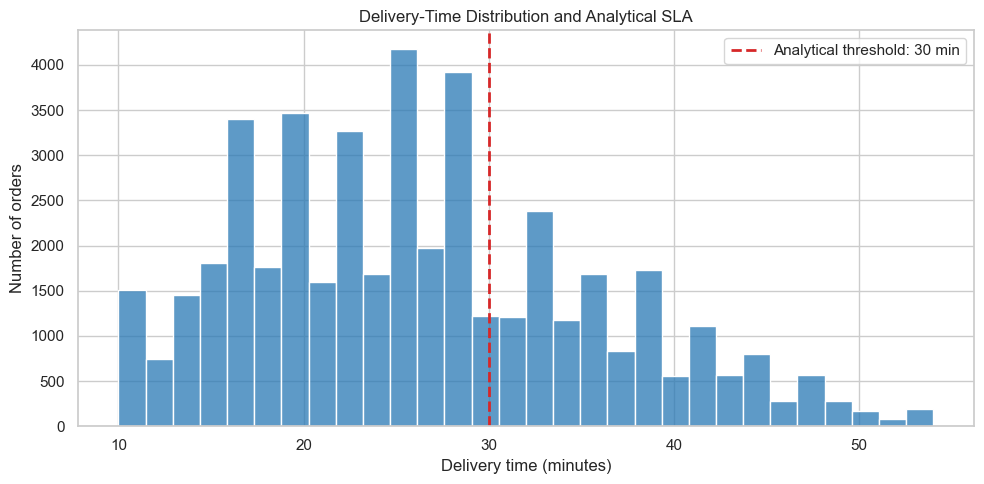

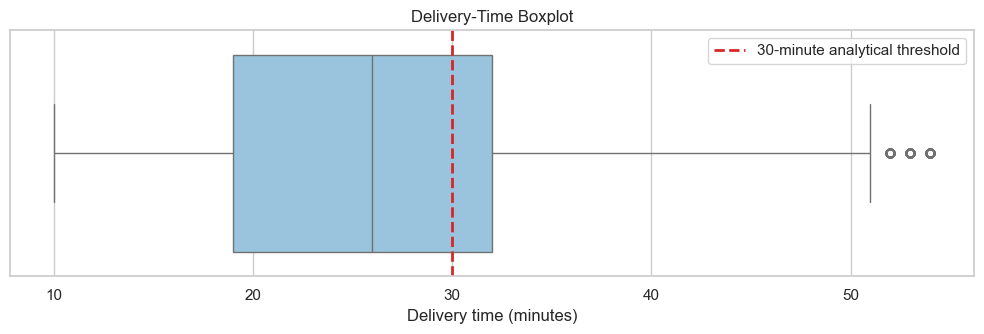

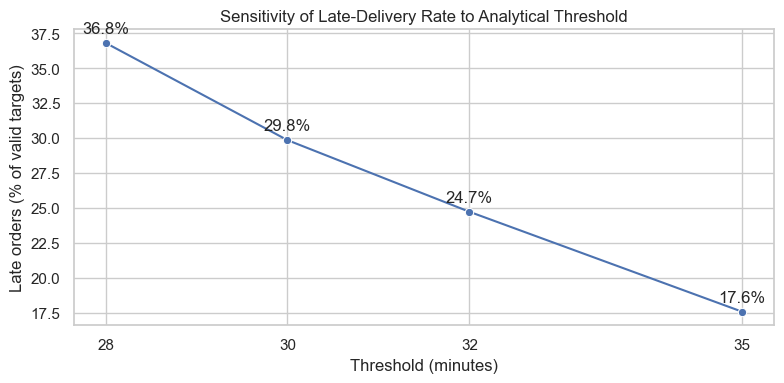

Target summary: {'count': 45593.0, 'mean': 26.29, 'std': 9.38, 'min': 10.0, '25%': 19.0, '50%': 26.0, '75%': 32.0, 'max': 54.0}


In [13]:
fig,ax=plt.subplots(figsize=(10,5)); sns.histplot(delivery_time.dropna(),bins=30,color='#2878B5',ax=ax)
ax.axvline(SLA_MINUTES,color='#D62728',linestyle='--',linewidth=2,label=f'Analytical threshold: {SLA_MINUTES} min')
ax.set(title='Delivery-Time Distribution and Analytical SLA',xlabel='Delivery time (minutes)',ylabel='Number of orders'); ax.legend()
savefig(fig,'delivery_time_distribution.png')
fig,ax=plt.subplots(figsize=(10,3.5)); sns.boxplot(x=delivery_time.dropna(),color='#8FC7E8',ax=ax)
ax.axvline(SLA_MINUTES,color='#D62728',linestyle='--',linewidth=2,label=f'{SLA_MINUTES}-minute analytical threshold')
ax.set(title='Delivery-Time Boxplot',xlabel='Delivery time (minutes)'); ax.legend()
savefig(fig,'delivery_time_boxplot.png')
fig,ax=plt.subplots(figsize=(8,4)); sns.lineplot(data=sla_sensitivity,x='sla_minutes',y='late_percent',marker='o',ax=ax)
ax.set(title='Sensitivity of Late-Delivery Rate to Analytical Threshold',xlabel='Threshold (minutes)',ylabel='Late orders (% of valid targets)',xticks=SENSITIVITY_THRESHOLDS)
for row in sla_sensitivity.itertuples(): ax.annotate(f'{row.late_percent:.1f}%',(row.sla_minutes,row.late_percent),xytext=(0,7),textcoords='offset points',ha='center')
savefig(fig,'sla_sensitivity_analysis.png')
print('Target summary:',delivery_time.describe().round(2).to_dict())

## 15. Time-Based Analysis

Order hour uses recorded `Time_Orderd`; weekday uses recorded `Order_Date`. Missing order times are excluded from hour analysis without filling them.

,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent,hour
0,by_order_hour,0.0,430,22.169767,21.0,7.201497,42,388,9.767442,90.232558,0.0
15,by_order_hour,8.0,1818,19.584158,19.0,5.630408,50,1768,2.750275,97.249725,8.0
16,by_order_hour,9.0,1947,19.543914,19.0,5.520633,31,1916,1.592193,98.407807,9.0
1,by_order_hour,10.0,1991,19.482170,19.0,5.517406,43,1948,2.159719,97.840281,10.0
2,by_order_hour,11.0,1962,26.380734,27.0,8.251917,588,1374,29.969419,70.030581,11.0
3,by_order_hour,12.0,892,26.826233,27.0,8.642940,285,607,31.950673,68.049327,12.0
4,by_order_hour,13.0,784,27.538265,27.0,8.574879,278,506,35.459184,64.540816,13.0
5,by_order_hour,14.0,791,27.537295,27.0,8.346503,267,524,33.754741,66.245259,14.0
6,by_order_hour,15.0,873,23.194731,23.0,6.925132,138,735,15.80756,84.19244,15.0
7,by_order_hour,16.0,709,22.943583,24.0,6.921038,105,604,14.809591,85.190409,16.0


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
0,by_weekday,Friday,7031,26.817380,26.0,9.514334,2267,4764,32.242924,67.757076
1,by_weekday,Monday,6207,26.254068,25.0,9.354586,1833,4374,29.531174,70.468826
2,by_weekday,Saturday,6290,26.099841,25.5,9.345707,1826,4464,29.030207,70.969793
3,by_weekday,Sunday,6249,26.401024,25.0,9.368138,1890,4359,30.244839,69.755161
4,by_weekday,Thursday,6348,25.183207,25.0,8.983467,1602,4746,25.236295,74.763705
5,by_weekday,Tuesday,6375,25.322196,25.0,9.062609,1623,4752,25.458824,74.541176
6,by_weekday,Wednesday,7093,27.759481,27.0,9.723371,2565,4528,36.162414,63.837586


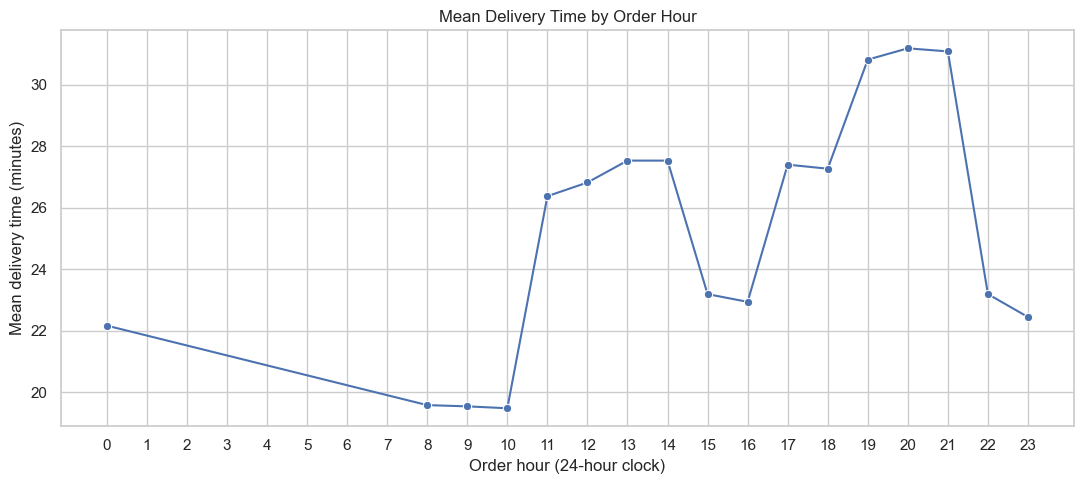

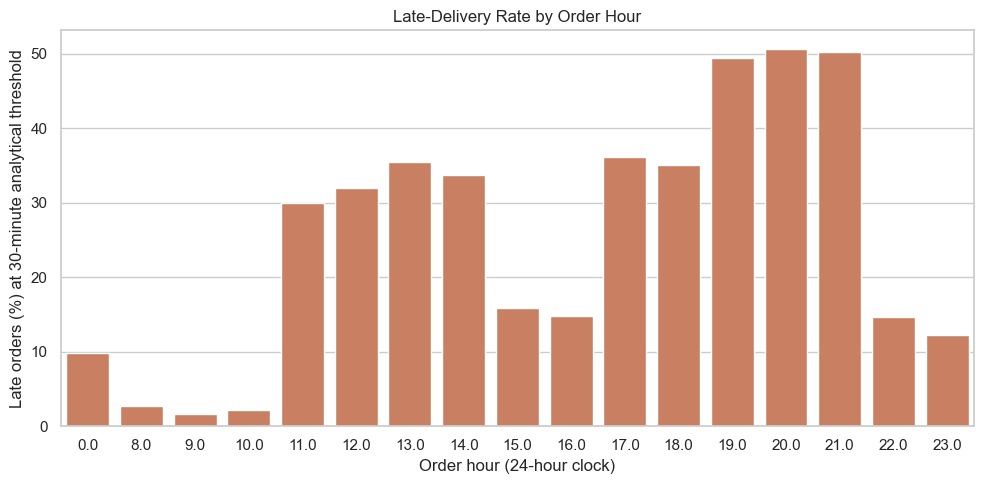

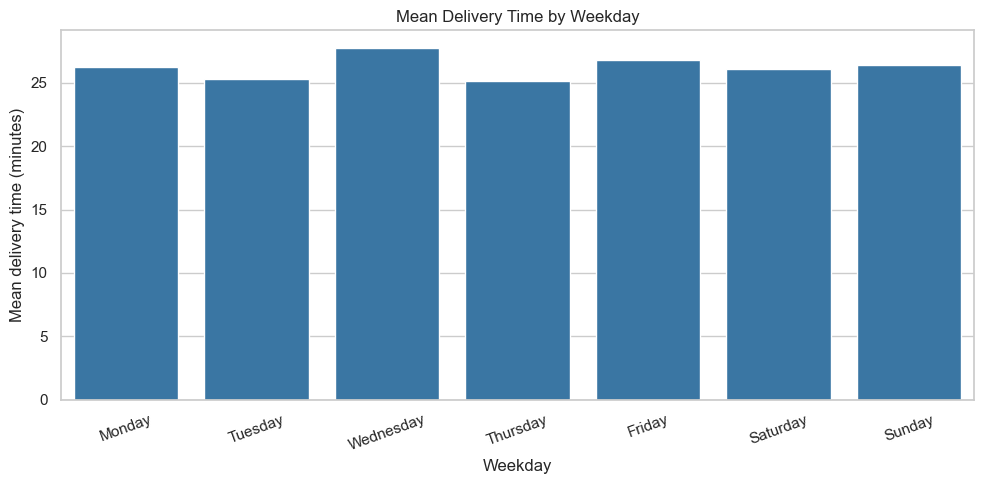

Missing order times excluded from hour grouping: 1731


In [14]:
hour=grouped(eda.order_hour,'by_order_hour')
hour['hour']=pd.to_numeric(hour.group,errors='coerce'); hour=hour.sort_values('hour')
week_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday=grouped(eda.weekday,'by_weekday')
display(hour); display(weekday)
fig,ax=plt.subplots(figsize=(11,5)); sns.lineplot(data=hour,x='hour',y='mean',marker='o',ax=ax)
ax.set(title='Mean Delivery Time by Order Hour',xlabel='Order hour (24-hour clock)',ylabel='Mean delivery time (minutes)',xticks=range(24))
savefig(fig,'delivery_time_by_order_hour.png')
late_rate_plot(hour,'Late-Delivery Rate by Order Hour','Order hour (24-hour clock)','late_rate_by_order_hour.png',rotation=0)
barplot(weekday,'Mean Delivery Time by Weekday','Weekday','delivery_time_by_weekday.png',week_order,20)
print('Missing order times excluded from hour grouping:',int(eda.order_hour.isna().sum()))

## 16. Weather and Traffic Analysis

Show group counts and summary statistics. `Unknown` is missing source data, not a measured weather/traffic class. Differences are observational.

,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
4,by_weather,Sunny,7284,21.856947,20.0,8.327210,912,6372,12.520593,87.479407
3,by_weather,Stormy,7586,25.870815,26.0,8.473273,1937,5649,25.533878,74.466122
2,by_weather,Sandstorms,7495,25.875517,26.0,8.618434,1945,5550,25.950634,74.049366
6,by_weather,Windy,7422,26.118836,26.0,8.615702,1971,5451,26.556184,73.443816
5,by_weather,Unknown,616,26.545455,26.0,9.474890,190,426,30.844156,69.155844
1,by_weather,Fog,7654,28.916122,28.0,10.129452,3352,4302,43.794095,56.205905
0,by_weather,Cloudy,7536,28.917330,28.0,10.084352,3299,4237,43.776539,56.223461


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
2,by_traffic,Low,15477,21.266977,20.0,6.799062,1218,14259,7.869742,92.130258
4,by_traffic,Unknown,601,26.542429,26.0,9.456847,186,415,30.948419,69.051581
3,by_traffic,Medium,10947,26.699644,27.0,8.560179,3555,7392,32.474651,67.525349
0,by_traffic,High,4425,27.240000,27.0,8.396012,1485,2940,33.559322,66.440678
1,by_traffic,Jam,14143,31.176624,31.0,9.940904,7162,6981,50.639893,49.360107


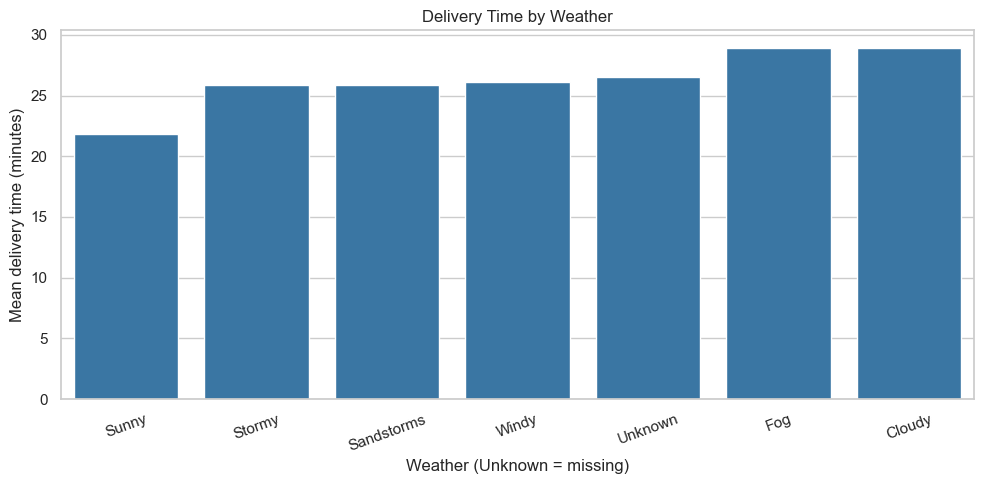

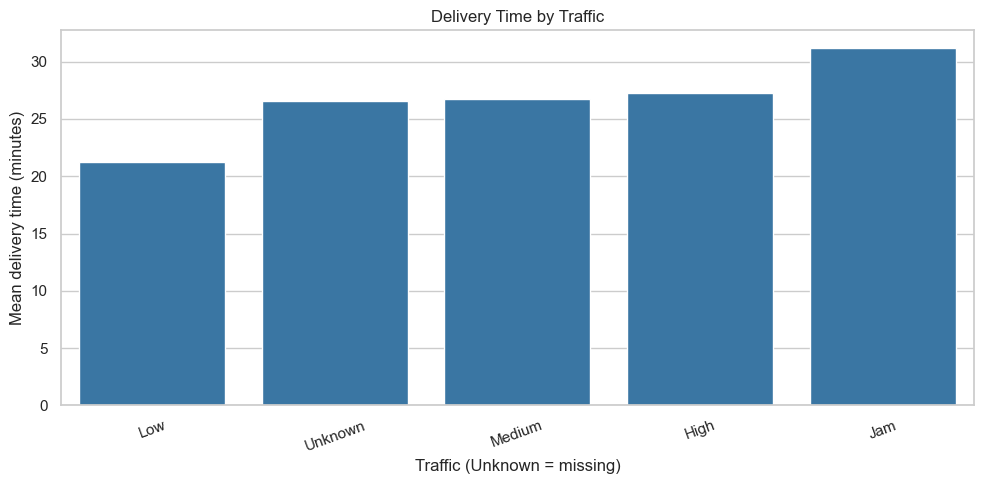

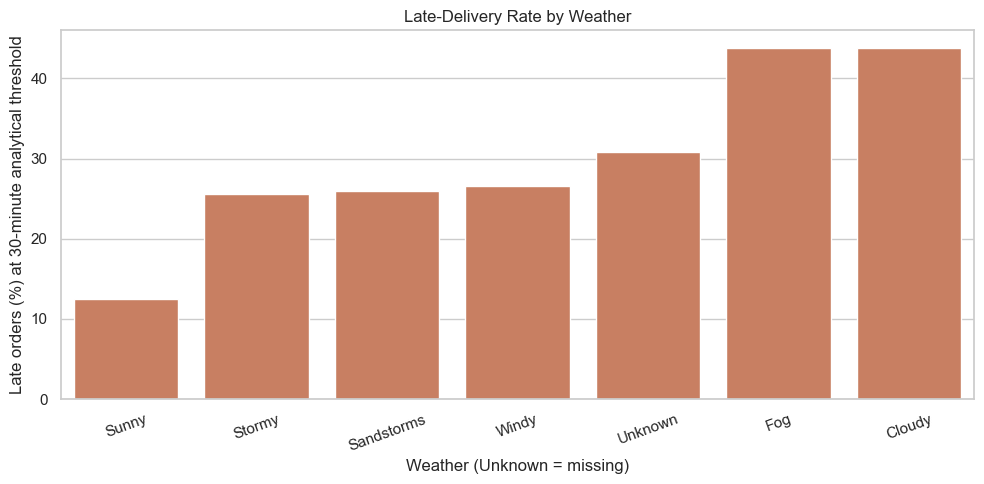

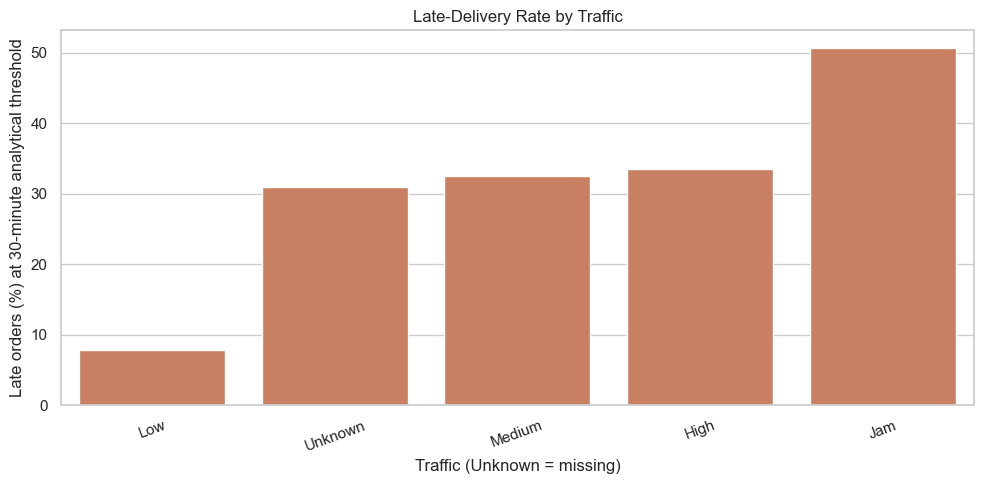

Weather/traffic capture timing is unverified; these fields are excluded from placement-time features. Rates are descriptive, not causal.


In [15]:
weather=grouped(data.Weatherconditions,'by_weather').sort_values('mean')
traffic=grouped(data.Road_traffic_density,'by_traffic').sort_values('mean')
display(weather); display(traffic)
barplot(weather,'Delivery Time by Weather','Weather (Unknown = missing)','delivery_time_by_weather.png',rotation=20)
barplot(traffic,'Delivery Time by Traffic','Traffic (Unknown = missing)','delivery_time_by_traffic.png',rotation=20)
late_rate_plot(weather,'Late-Delivery Rate by Weather','Weather (Unknown = missing)','late_rate_by_weather.png',rotation=20)
late_rate_plot(traffic,'Late-Delivery Rate by Traffic','Traffic (Unknown = missing)','late_rate_by_traffic.png',rotation=20)
print('Weather/traffic capture timing is unverified; these fields are excluded from placement-time features. Rates are descriptive, not causal.')

## 17. Distance Analysis

Only valid GPS rows are analyzed geographically. The distance-time scatter uses a reproducible sample for readability; the full valid sample is used for statistics and correlations.

GPS-valid distance sample: 41522 | invalid GPS excluded: 4071
Distance-time Pearson r: 0.321 Spearman rho: 0.32


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
0,by_distance_quartile,"(1.4640000000000002, 4.658]",10393,22.087655,21.0,7.382158,1255,9138,12.075435,87.924565
1,by_distance_quartile,"(13.681, 20.97]",10371,29.871372,29.0,9.841112,4693,5678,45.251181,54.748819
2,by_distance_quartile,"(4.658, 9.193]",10376,24.397456,25.0,8.006184,2209,8167,21.289514,78.710486
3,by_distance_quartile,"(9.193, 13.681]",10382,28.912445,28.0,9.780066,4286,6096,41.28299,58.71701


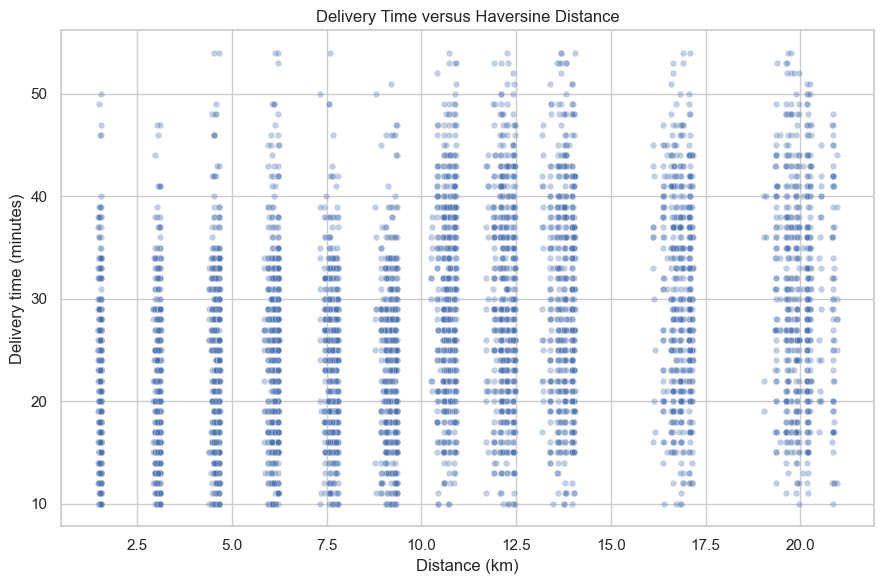

In [16]:
dframe=pd.DataFrame({'distance_km':distance_km,'delivery_time':delivery_time,'is_late':prepared.is_late}).dropna()
dframe['distance_group']=pd.qcut(dframe.distance_km,4,duplicates='drop').astype('string')
distance_groups=dframe.groupby('distance_group').agg(
    n=('delivery_time','count'),mean=('delivery_time','mean'),median=('delivery_time','median'),std=('delivery_time','std'),
    late_count=('is_late',lambda values:int(values.eq(1).sum())),on_time_count=('is_late',lambda values:int(values.eq(0).sum()))).reset_index().rename(columns={'distance_group':'group'})
distance_groups['late_percent']=distance_groups.late_count/distance_groups.n*100
distance_groups['on_time_percent']=distance_groups.on_time_count/distance_groups.n*100
distance_groups.insert(0,'analysis','by_distance_quartile'); groups.append(distance_groups)
pearson=float(dframe[['distance_km','delivery_time']].corr(method='pearson').iloc[0,1])
spearman=float(dframe[['distance_km','delivery_time']].corr(method='spearman').iloc[0,1])
print('GPS-valid distance sample:',len(dframe),'| invalid GPS excluded:',int(gps_invalid.sum()))
print('Distance-time Pearson r:',round(pearson,3),'Spearman rho:',round(spearman,3))
display(distance_groups)
plot=dframe.sample(min(6000,len(dframe)),random_state=42)
fig,ax=plt.subplots(figsize=(9,6)); sns.scatterplot(data=plot,x='distance_km',y='delivery_time',alpha=.35,s=22,ax=ax)
ax.set(title='Delivery Time versus Haversine Distance',xlabel='Distance (km)',ylabel='Delivery time (minutes)')
savefig(fig,'delivery_time_vs_distance.png')

## 18. Rider and Order Analysis

The dataset contains no rider-tenure or years-of-experience column. Rider age is analyzed separately as **Delivery Time by Rider Age** and is not used as a substitute for professional experience. Age validation in this analysis uses the inclusive 18-80 range; invalid source values are reported and excluded from age summaries without changing the source or PS1 file. For consistency across the project, rider age values are considered valid for analysis when they fall between 18 and 80 years, inclusive. This is a data-validation rule and does not represent rider professional experience. Rating is a separate historical measure. The `multiple_deliveries` source contains encoded values; because available local metadata does not define their meaning, charts label them `Encoded value N` and make no delivery-count claim. Other categorical summaries retain `Unknown` and show sample counts.

Delivery Time by Rider Age


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent,age
0,by_observed_rider_age,20,2136,22.898876,21.0,8.620170,371,1765,17.368914,82.631086,20
1,by_observed_rider_age,21,2153,22.908500,22.0,8.629265,386,1767,17.928472,82.071528,21
2,by_observed_rider_age,22,2196,22.934426,22.0,8.439752,374,1822,17.030965,82.969035,22
3,by_observed_rider_age,23,2087,23.197413,22.0,8.433903,383,1704,18.351701,81.648299,23
4,by_observed_rider_age,24,2210,23.059729,22.0,8.732536,406,1804,18.371041,81.628959,24
5,by_observed_rider_age,25,2174,22.819227,22.0,8.544784,380,1794,17.479301,82.520699,25
6,by_observed_rider_age,26,2159,22.948124,22.0,8.546720,387,1772,17.924965,82.075035,26
7,by_observed_rider_age,27,2150,23.053023,22.0,8.733955,396,1754,18.418605,81.581395,27
8,by_observed_rider_age,28,2179,23.166590,22.0,8.682929,408,1771,18.724185,81.275815,28
9,by_observed_rider_age,29,2191,22.916933,21.0,8.681342,391,1800,17.845733,82.154267,29


Observed rating


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent,rating
0,by_observed_rating,1.0,38,26.000000,26.5,6.758378,7,31,18.421053,81.578947,1.0
1,by_observed_rating,2.5,20,37.300000,35.5,4.473313,20,0,100.0,0.0,2.5
2,by_observed_rating,2.6,22,38.590909,39.0,4.338741,22,0,100.0,0.0,2.6
3,by_observed_rating,2.7,22,35.863636,36.5,3.745416,22,0,100.0,0.0,2.7
4,by_observed_rating,2.8,19,36.631579,37.0,3.989020,19,0,100.0,0.0,2.8
5,by_observed_rating,2.9,19,38.526316,39.0,3.935147,19,0,100.0,0.0,2.9
6,by_observed_rating,3.0,6,32.666667,32.5,1.211060,6,0,100.0,0.0,3.0
7,by_observed_rating,3.1,29,36.551724,35.0,4.717643,29,0,100.0,0.0,3.1
8,by_observed_rating,3.2,29,36.344828,36.0,4.295146,29,0,100.0,0.0,3.2
9,by_observed_rating,3.3,25,36.040000,36.0,3.973663,25,0,100.0,0.0,3.3


Order type


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
1,by_order_type,Drinks,11322,26.187953,25.0,9.298465,3378,7944,29.835718,70.164282
0,by_order_type,Buffet,11280,26.283511,26.0,9.411344,3347,7933,29.671986,70.328014
3,by_order_type,Snack,11533,26.286309,26.0,9.399147,3440,8093,29.827452,70.172548
2,by_order_type,Meal,11458,26.419270,26.0,9.424849,3441,8017,30.031419,69.968581


... (4 outputs left out)

Festival


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
1,by_festival,Unknown,228,11.166667,11.0,1.234002,0,228,0.0,100.0
0,by_festival,No,44469,25.984843,25.0,9.013116,12710,31759,28.581709,71.418291
2,by_festival,Yes,896,45.517857,45.0,4.001915,896,0,100.0,0.0


City


,analysis,group,n,mean,median,std,late_count,on_time_count,late_percent,on_time_percent
2,by_city,Unknown,1200,22.058333,21.0,8.308577,185,1015,15.416667,84.583333
3,by_city,Urban,10136,22.984017,22.0,8.866011,1891,8245,18.656275,81.343725
0,by_city,Metropolitan,34093,27.315226,27.0,9.184435,11366,22727,33.338222,66.661778
1,by_city,Semi-Urban,164,49.731707,49.0,2.693089,164,0,100.0,0.0


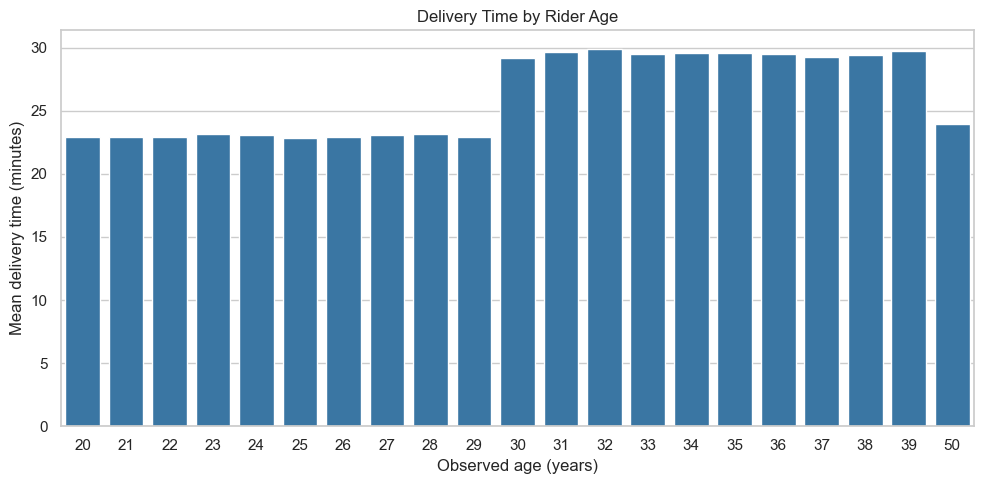

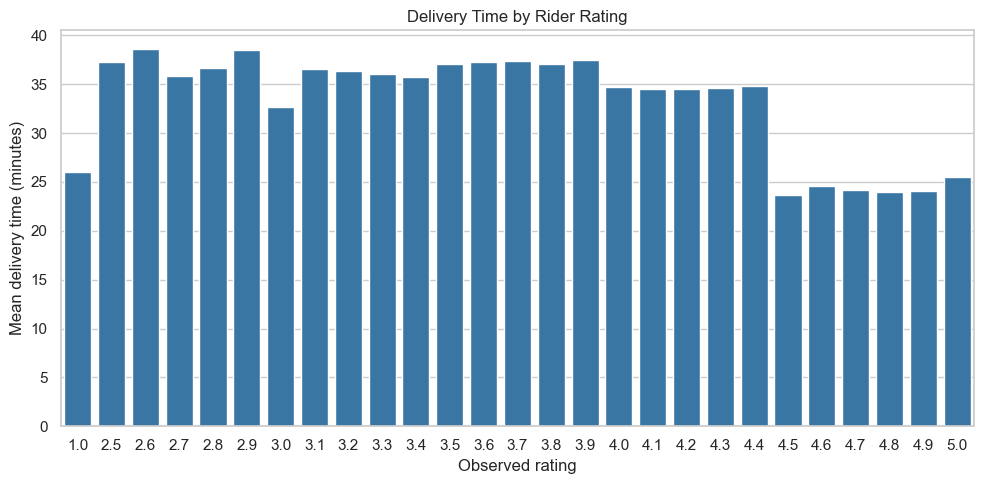

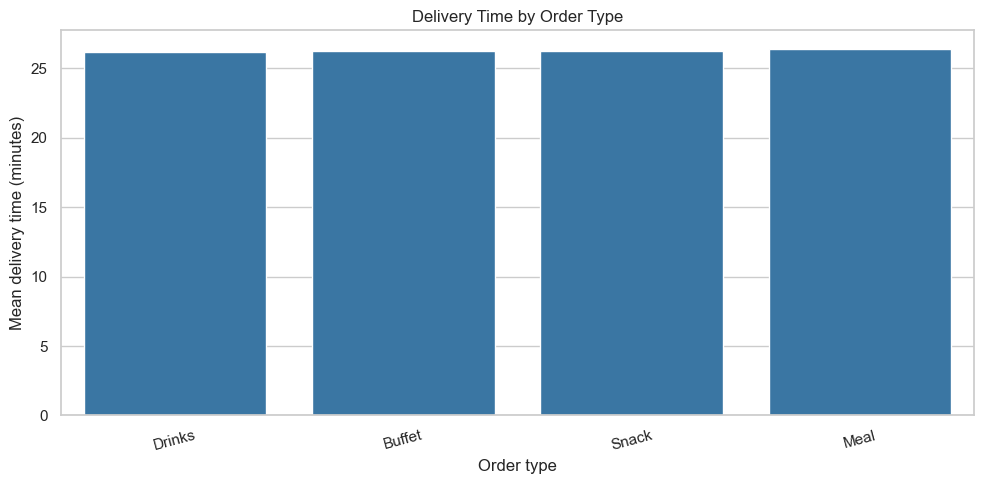

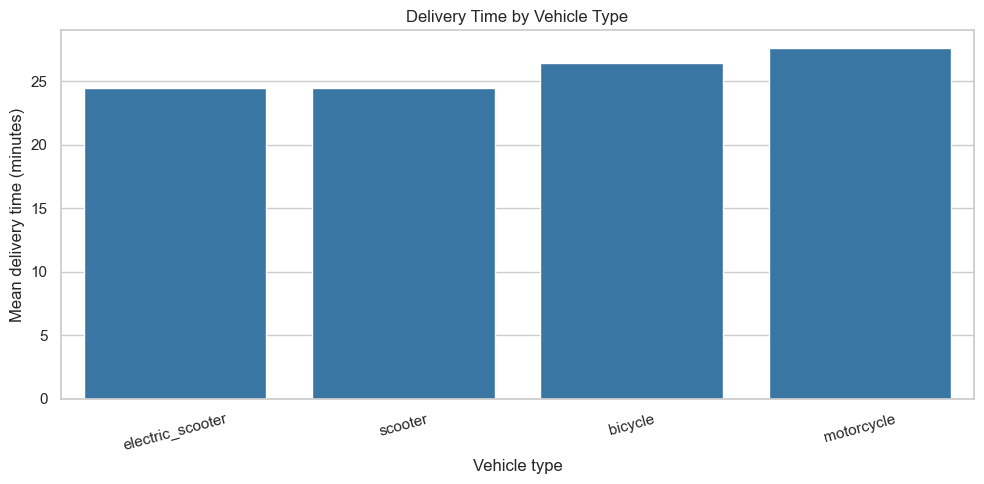

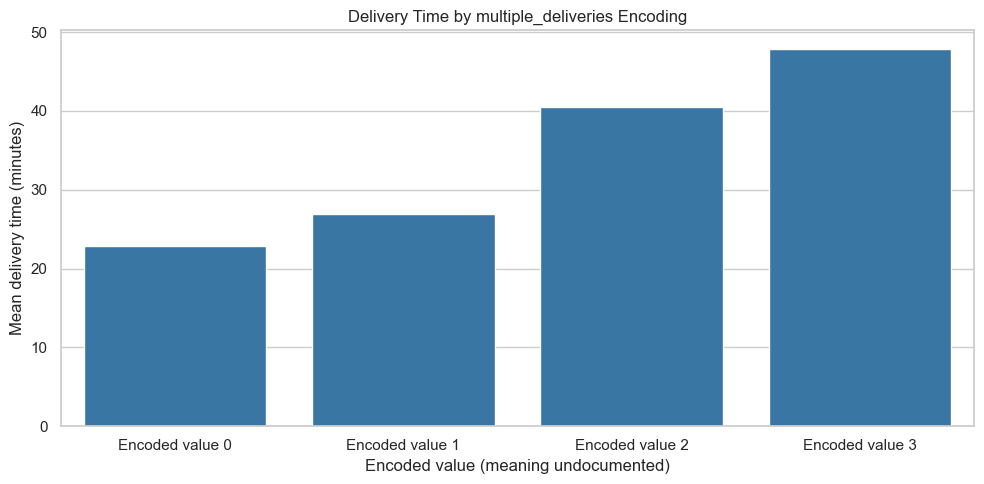

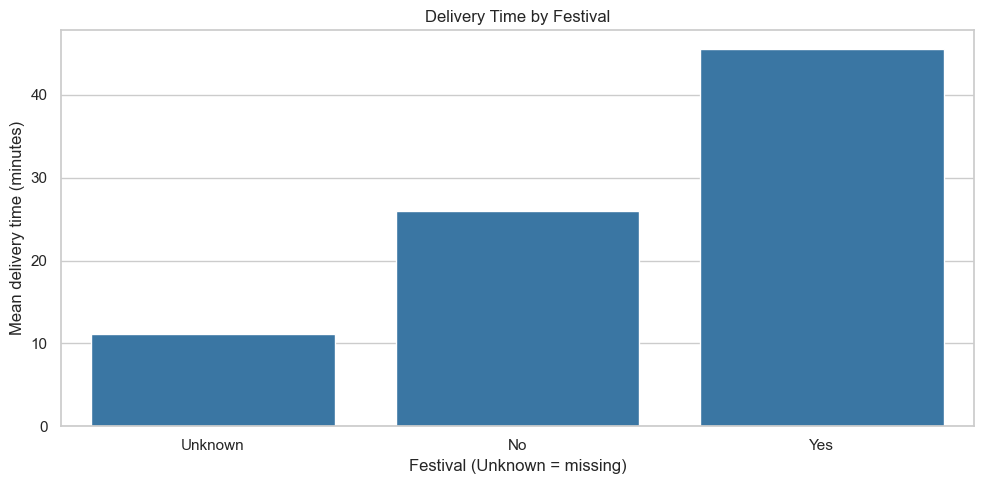

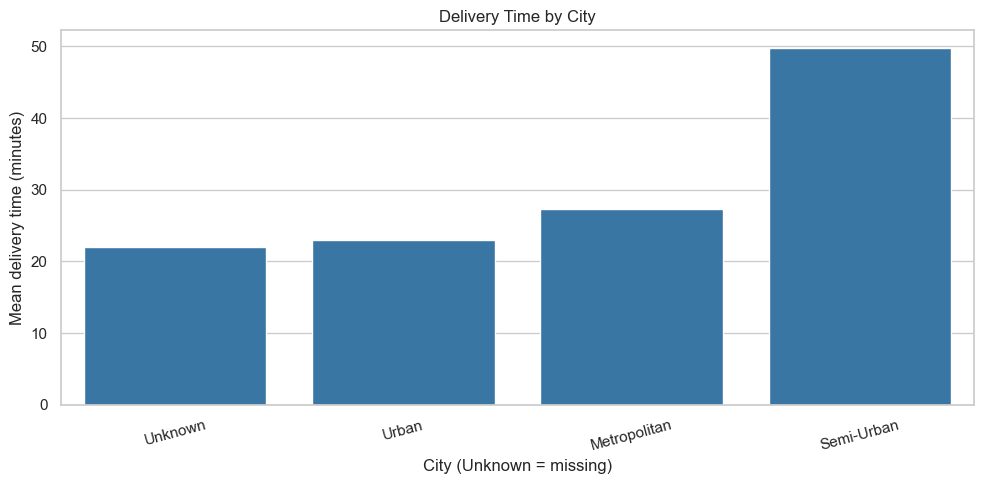

All comparisons are descriptive; rider age is not rider experience and no causal inference is made.


In [17]:
age_summary=grouped(age,'by_observed_rider_age',age_ok); age_summary['age']=pd.to_numeric(age_summary.group); age_summary=age_summary.sort_values('age')
rating_summary=grouped(rating,'by_observed_rating',rating_ok); rating_summary['rating']=pd.to_numeric(rating_summary.group); rating_summary=rating_summary.sort_values('rating')
order_type=grouped(data.Type_of_order,'by_order_type').sort_values('mean')
vehicle_type=grouped(data.Type_of_vehicle,'by_vehicle_type').sort_values('mean')
multi=grouped(multiple_labels,'by_multiple_delivery_encoding',multiple_ok)
multi['sort']=pd.to_numeric(multi.group.str.extract(r'Encoded value ([-+]?\d+)',expand=False),errors='coerce'); multi=multi.sort_values('sort')
festival=grouped(data.Festival,'by_festival').sort_values('mean')
city=grouped(data.City,'by_city').sort_values('mean')
for title,table in [('Delivery Time by Rider Age',age_summary),('Observed rating',rating_summary),('Order type',order_type),
                    ('Vehicle type',vehicle_type),('multiple_deliveries encoded values',multi),('Festival',festival),('City',city)]:
    print(title); display(table)
barplot(age_summary,'Delivery Time by Rider Age','Observed age (years)','delivery_time_by_rider_age.png')
barplot(rating_summary,'Delivery Time by Rider Rating','Observed rating','delivery_time_by_rider_rating.png')
barplot(order_type,'Delivery Time by Order Type','Order type','delivery_time_by_order_type.png',rotation=15)
barplot(vehicle_type,'Delivery Time by Vehicle Type','Vehicle type','delivery_time_by_vehicle_type.png',rotation=15)
barplot(multi,'Delivery Time by multiple_deliveries Encoding','Encoded value (meaning undocumented)','delivery_time_by_multiple_deliveries.png')
barplot(festival,'Delivery Time by Festival','Festival (Unknown = missing)','delivery_time_by_festival.png')
barplot(city,'Delivery Time by City','City (Unknown = missing)','delivery_time_by_city.png',rotation=15)
print('All comparisons are descriptive; rider age is not rider experience and no causal inference is made.')

## 19. Correlation Analysis

Use only numeric measures with interpretable scales. Correlations use pairwise complete observations; categorical codes are not treated as continuous.

,delivery_time_minutes,distance_km,rider_age_years_observed,rider_rating_observed
delivery_time_minutes,1.000000,0.321127,0.300293,-0.341199
distance_km,0.321127,1.000000,-0.000824,-0.105052
rider_age_years_observed,0.300293,-0.000824,1.000000,-0.117577
rider_rating_observed,-0.341199,-0.105052,-0.117577,1.000000


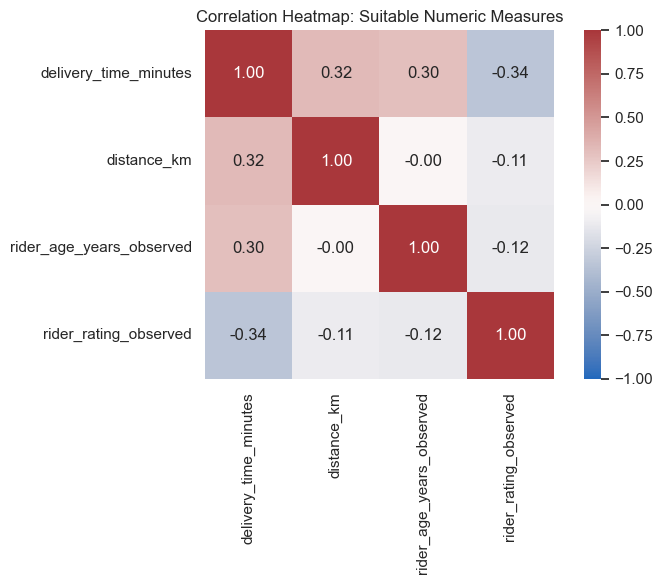

In [18]:
corr_data=pd.DataFrame({'delivery_time_minutes':delivery_time,'distance_km':distance_km,
 'rider_age_years_observed':age.where(age_ok),'rider_rating_observed':rating.where(rating_ok)})
correlation=corr_data.corr(min_periods=100)
display(correlation)
fig,ax=plt.subplots(figsize=(8,6)); sns.heatmap(correlation,annot=True,fmt='.2f',cmap='vlag',center=0,vmin=-1,vmax=1,square=True,ax=ax)
ax.set(title='Correlation Heatmap: Suitable Numeric Measures')
savefig(fig,'correlation_heatmap.png')
correlation.rename_axis('variable').to_csv(EDA/'numeric_correlation_matrix.csv')

## 20. Three Key Findings

Findings are recalculated using the 30-minute analytical SLA and include means, late-delivery rates, and sample counts. The threshold is not an officially guaranteed delivery promise. Findings are descriptive, not causal. Each finding also carries the food-delivery dataset applicability limitation.

In [19]:
def get_group(table,value):
    match=table.loc[table.group.astype('string').eq(str(value))]
    if match.empty: raise ValueError(f'Required comparison group not found: {value}')
    return match.iloc[0]
hours=hour.loc[hour.n>=300]
highest=hours.loc[hours['mean'].idxmax()]; lowest=hours.loc[hours['mean'].idxmin()]
fog=get_group(weather,'Fog'); sunny=get_group(weather,'Sunny')
encoded0=get_group(multi,'Encoded value 0'); encoded1=get_group(multi,'Encoded value 1')
findings=[
 {'title':'Delivery time and late share vary by order hour',
  'observation':f"Hour {int(highest.hour):02d}:00 averaged {highest['mean']:.2f} min (n={int(highest.n):,}; late {highest.late_percent:.1f}%); hour {int(lowest.hour):02d}:00 averaged {lowest['mean']:.2f} min (n={int(lowest.n):,}; late {lowest.late_percent:.1f}%).",
  'numerical_evidence':{'high_hour':int(highest.hour),'high_mean_min':float(highest['mean']),'high_n':int(highest.n),'high_late_percent':float(highest.late_percent),
              'low_hour':int(lowest.hour),'low_mean_min':float(lowest['mean']),'low_n':int(lowest.n),'low_late_percent':float(lowest.late_percent),
              'difference_min':float(highest['mean']-lowest['mean'])},
  'sample_count':{'high_hour':int(highest.n),'low_hour':int(lowest.n)},
  'operational_importance':'Review staffing and demand coverage at higher-duration hours.',
  'limitation':'Missing order times are excluded; hour effects may reflect other factors and do not establish cause.',
  'sla_minutes':SLA_MINUTES,'dataset_applicability':DATASET_LIMITATION},
 {'title':'Observed weather groups have different descriptive outcomes',
  'observation':f"Fog averaged {fog['mean']:.2f} min (n={int(fog.n):,}; late {fog.late_percent:.1f}%); Sunny averaged {sunny['mean']:.2f} min (n={int(sunny.n):,}; late {sunny.late_percent:.1f}%).",
  'numerical_evidence':{'fog_mean_min':float(fog['mean']),'fog_n':int(fog.n),'fog_late_percent':float(fog.late_percent),'sunny_mean_min':float(sunny['mean']),
              'sunny_n':int(sunny.n),'sunny_late_percent':float(sunny.late_percent),'difference_min':float(fog['mean']-sunny['mean'])},
  'sample_count':{'fog':int(fog.n),'sunny':int(sunny.n)},
  'operational_importance':'Weather observations can be reviewed during contingency planning.',
  'limitation':'Weather capture timing is unverified; this association is descriptive, not causal, and weather is excluded from placement-time features.',
  'sla_minutes':SLA_MINUTES,'dataset_applicability':DATASET_LIMITATION},
 {'title':'Delivery outcomes vary across undocumented multiple_deliveries encodings',
  'observation':f"Encoded value 0 averaged {encoded0['mean']:.2f} min (n={int(encoded0.n):,}; late {encoded0.late_percent:.1f}%); encoded value 1 averaged {encoded1['mean']:.2f} min (n={int(encoded1.n):,}; late {encoded1.late_percent:.1f}%).",
  'numerical_evidence':{'encoded_0_mean_min':float(encoded0['mean']),'encoded_0_n':int(encoded0.n),'encoded_0_late_percent':float(encoded0.late_percent),
              'encoded_1_mean_min':float(encoded1['mean']),'encoded_1_n':int(encoded1.n),'encoded_1_late_percent':float(encoded1.late_percent),
              'difference_min':float(encoded1['mean']-encoded0['mean'])},
  'sample_count':{'encoded_0':int(encoded0.n),'encoded_1':int(encoded1.n)},
  'operational_importance':'Investigate the field definition with the data owner before using it operationally.',
  'limitation':'Meanings of encoded values are not documented in available project metadata; no delivery-count interpretation is asserted. PS1-imputed source values were excluded.',
  'sla_minutes':SLA_MINUTES,'dataset_applicability':DATASET_LIMITATION},
]
for i,f in enumerate(findings,1): print(i,f['title'],'-',f['observation'],'| Samples:',f['sample_count'])

1 Delivery time and late share vary by order hour - Hour 20:00 averaged 31.19 min (n=4,539; late 50.6%); hour 10:00 averaged 19.48 min (n=1,991; late 2.2%). | Samples: {'high_hour': 4539, 'low_hour': 1991}
2 Observed weather groups have different descriptive outcomes - Fog averaged 28.92 min (n=7,654; late 43.8%); Sunny averaged 21.86 min (n=7,284; late 12.5%). | Samples: {'fog': 7654, 'sunny': 7284}
3 Delivery outcomes vary across undocumented multiple_deliveries encodings - Encoded value 0 averaged 22.88 min (n=14,095; late 18.1%); encoded value 1 averaged 26.86 min (n=28,159; late 30.3%). | Samples: {'encoded_0': 14095, 'encoded_1': 28159}


## 21. Streamlit Output Preparation

Save grouped EDA results, findings, the updated PS2 JSON, and a manifest of every artifact. Streamlit can consume these regular files without executing Jupyter.

In [20]:
summary['rider_experience']={'available':RIDER_EXPERIENCE_AVAILABLE,
 'limitation':'Rider tenure/years of experience is not present; age is not a substitute.',
 'age_analysis_range':[AGE_MIN,AGE_MAX],'age_validation_range':'18-80',
 'invalid_observed_age_count':int(age_invalid.sum()),'age_rule_note':'Module 02 age summaries use the 18-80 validation range.'}
summary['multiple_deliveries']={'observed_encoded_values':sorted(int(v) for v in multiple.dropna().unique()),
 'meanings_verified':MULTIPLE_DELIVERY_MEANINGS_VERIFIED,'interpretation':'Neutral encoded-value labels; no data dictionary was available.'}
validation.loc[len(validation)] = metric('invalid_age_18_80_records',int(age_invalid.sum()),'Temporary analysis mask only; original values and PS1 data remain unchanged.')
validation.to_csv(PS2/'data_validation_report.csv',index=False)
group_summary=pd.concat(groups,ignore_index=True)
group_summary['sample_count']=group_summary.n.astype('int64')
group_summary.to_csv(EDA/'eda_group_summaries.csv',index=False)
with (EDA/'key_findings.json').open('w',encoding='utf-8') as f: json.dump(findings,f,indent=2,ensure_ascii=False,allow_nan=False)
summary['eda']={'group_summary':'outputs/eda/eda_group_summaries.csv','charts':[p.relative_to(ROOT).as_posix() for p in charts],
 'chart_count':len(charts),'distance_pearson':pearson,'distance_spearman':spearman,
 'missing_order_times_excluded':int(eda.order_hour.isna().sum()),
 'rider_experience_field':None,'rider_limitation':'Rider tenure/experience is unavailable; age is not a substitute.',
 'dataset_applicability_limitation':DATASET_LIMITATION,
 'multiple_deliveries_interpretation':'Undocumented encoded values; use neutral labels only.',
 'sla_sensitivity_report':'outputs/ps2/sla_sensitivity_analysis.csv'}
with (PS2/'delay_lens_summary.json').open('w',encoding='utf-8') as f: json.dump(summary,f,indent=2,ensure_ascii=False,allow_nan=False)
manifest_path=OUT/'ps2_ps3_output_manifest.json'
manifest_items=[
 ('data/model_ready_data.csv','All PS1 rows with unchanged target, 30-minute analytical late labels, and the single canonical distance_km field.','Reusable prepared dataset.','Delay Intelligence'),
 ('outputs/ps2/delay_lens_summary.json','30-minute analytical SLA counts, percentages, sensitivity, feature summary, rider limitation, and dataset applicability.','Summary cards/status.','Delay Intelligence'),
 ('outputs/ps2/feature_availability_report.csv','Timing and leakage decision for each column.','Explain safe prediction inputs.','Model Input Review'),
 ('outputs/ps2/data_validation_report.csv','Record, target, GPS, distance, SLA, age-analysis, and applicability checks.','Quality indicators.','Data Quality'),
 ('outputs/ps2/sla_sensitivity_analysis.csv','Late-rate sensitivity at 28, 30, 32, and 35 minutes.','Threshold sensitivity display.','Delay Intelligence'),
 ('outputs/eda/eda_group_summaries.csv','Long-form group counts, means, on-time/late counts, and 30-minute rates.','Interactive descriptive summaries.','Exploratory Analytics'),
 ('outputs/eda/numeric_correlation_matrix.csv','Pairwise correlation matrix.','Correlation display.','Exploratory Analytics'),
 ('outputs/eda/key_findings.json','Three recalculated findings with late rates, evidence, and applicability limitations.','Evidence cards.','Key Findings'),
]
for p in charts: manifest_items.append((p.relative_to(ROOT).as_posix(),p.stem.replace('_',' ')+' chart; late rates use the 30-minute analytical threshold where applicable.','Presentation-ready PNG.','Exploratory Analytics'))
manifest={'manifest_version':'1.0','project':'Quick-Commerce Delivery Intelligence','sla_status':SLA_STATUS,
 'feature_availability_source':'outputs/ps2/feature_availability_report.csv',
 'order_placement_features':{'regression':REGRESSION_FEATURES,'classification':CLASSIFICATION_FEATURES,
   'targets':TARGET_COLUMNS,'availability_assumptions':AVAILABILITY_ASSUMPTIONS},
 'sla':{'minutes':SLA_MINUTES,'official_customer_promise_confirmed':SLA_OFFICIAL_CONFIRMATION,
        'description':summary['sla']['statement'],'sensitivity_thresholds':SENSITIVITY_THRESHOLDS},
 'rider_experience':{'available':RIDER_EXPERIENCE_AVAILABLE,'description':'Rider experience/tenure is unavailable in this dataset; rider age is analyzed separately and is not a proxy.'},
 'dataset_applicability_limitation':DATASET_LIMITATION,
 'multiple_deliveries':{'meanings_verified':MULTIPLE_DELIVERY_MEANINGS_VERIFIED,'description':'Encoded values are shown neutrally because no local data dictionary was available.'},
 'outputs':[{'filename':Path(path).name,'relative_path':path,'description':desc,'purpose':purpose,'streamlit_page':page}
            for path,desc,purpose,page in manifest_items]}
with manifest_path.open('w',encoding='utf-8') as f: json.dump(manifest,f,indent=2,ensure_ascii=False,allow_nan=False)
print('Group summaries:',len(group_summary),'| charts:',len(charts),'| manifest entries:',len(manifest_items))
print('Manifest:',manifest_path.relative_to(ROOT))

Group summaries: 107 | charts: 19 | manifest entries: 27
Manifest: outputs\ps2_ps3_output_manifest.json


## 22. Final Validation

Assertions verify source/target integrity, no row loss or duplication, 18-80 age validation, 30-minute SLA labels, no leakage features, valid distances only, missing timestamps, saved files, manifest paths, charts, and unchanged PS1 files.

In [21]:
assert FINAL_PATH.is_file() and SOURCE_PATH.is_file()
assert len(data)==len(model_ready)==source_rows==rows_before
assert model_ready.columns.tolist().count('distance_km')==1 and 'Distance_km' not in model_ready.columns
assert int(model_ready.duplicated().sum())==int(data.duplicated().sum())
assert model_ready.ID.astype('string').str.strip().is_unique
assert np.array_equal(model_ready[TARGET_SOURCE].to_numpy(float),original_target.to_numpy(float))
assert np.array_equal(model_ready.delivery_time.to_numpy(float),original_target.to_numpy(float))
assert SLA_MINUTES==30 and SLA_OFFICIAL_CONFIRMATION is False
assert model_ready.is_late.isna().equals(model_ready.delivery_time.isna())
assert model_ready.loc[model_ready.delivery_time.le(SLA_MINUTES),'is_late'].eq(0).all()
assert model_ready.loc[model_ready.delivery_time.gt(SLA_MINUTES),'is_late'].eq(1).all()
assert model_ready.is_late.dropna().isin([0,1]).all()
assert late_count+on_time_count==valid_target_count==int(model_ready.delivery_time.notna().sum())
assert abs(late_percent+on_time_percent-100)<1e-10
assert sla_sensitivity.sla_minutes.tolist()==[28,30,32,35]
assert int(sla_sensitivity.loc[sla_sensitivity.sla_minutes.eq(30),'late_count'].iloc[0])==late_count
assert AGE_MIN==18 and AGE_MAX==80
assert set(REGRESSION_FEATURES)<=set(model_ready.columns)
assert set(CLASSIFICATION_FEATURES)<=set(model_ready.columns)
assert 'Time_Order_picked' not in REGRESSION_FEATURES+CLASSIFICATION_FEATURES
assert 'is_late' not in REGRESSION_FEATURES+CLASSIFICATION_FEATURES
assert 'delivery_time' not in REGRESSION_FEATURES+CLASSIFICATION_FEATURES
assert not set(REGRESSION_FEATURES+CLASSIFICATION_FEATURES)&set(TARGET_COLUMNS+POST_ORDER_FEATURES+UNVERIFIED_FEATURES)
assert '18-80' in summary['rider_experience']['age_validation_range']
assert age_invalid.sum()==(age.notna() & ~age.between(18,80)).sum()
assert not RIDER_EXPERIENCE_AVAILABLE and MULTIPLE_DELIVERY_MEANINGS_VERIFIED is False
assert multi.group.str.startswith('Encoded value ').all()
for feature_list in [REGRESSION_FEATURES,CLASSIFICATION_FEATURES]:
    assert set(feature_list)<=set(model_ready.columns)
    assert not set(feature_list)&set(TARGET_COLUMNS+POST_ORDER_FEATURES+UNVERIFIED_FEATURES)
assert model_ready.loc[gps_invalid,'distance_km'].isna().all()
dv=model_ready.loc[gps_valid,'distance_km'].to_numpy(float)
assert len(dv)==int(gps_valid.sum()) and np.isfinite(dv).all() and (dv>=0).all()
assert int(eda.order_hour.isna().sum())==int(data.Time_Orderd.isna().sum())
expected_charts={'delivery_time_distribution.png','delivery_time_boxplot.png','sla_sensitivity_analysis.png',
 'delivery_time_by_order_hour.png','late_rate_by_order_hour.png','delivery_time_by_weekday.png',
 'delivery_time_by_weather.png','delivery_time_by_traffic.png','late_rate_by_weather.png','late_rate_by_traffic.png',
 'delivery_time_vs_distance.png','delivery_time_by_rider_age.png','delivery_time_by_rider_rating.png',
 'delivery_time_by_order_type.png','delivery_time_by_vehicle_type.png','delivery_time_by_multiple_deliveries.png',
 'delivery_time_by_festival.png','delivery_time_by_city.png','correlation_heatmap.png'}
assert {p.name for p in charts}==expected_charts
required=[MODEL_PATH,PS2/'delay_lens_summary.json',PS2/'feature_availability_report.csv',
 PS2/'data_validation_report.csv',PS2/'sla_sensitivity_analysis.csv',EDA/'eda_group_summaries.csv',
 EDA/'numeric_correlation_matrix.csv',EDA/'key_findings.json',manifest_path]+charts
assert all(p.is_file() and p.stat().st_size>0 for p in required)
model_reopened=pd.read_csv(MODEL_PATH)
assert len(model_reopened)==len(model_ready)
assert model_reopened.columns.tolist().count('distance_km')==1 and 'Distance_km' not in model_reopened.columns
assert np.array_equal(pd.to_numeric(model_reopened['is_late'],errors='coerce').to_numpy(float),
                       pd.to_numeric(model_ready['is_late'],errors='coerce').to_numpy(float),equal_nan=True)
assert not pd.read_csv(PS2/'feature_availability_report.csv').empty
assert not pd.read_csv(PS2/'data_validation_report.csv').empty
assert not pd.read_csv(EDA/'eda_group_summaries.csv').empty
assert pd.read_csv(EDA/'numeric_correlation_matrix.csv',index_col=0).shape==correlation.shape
with (PS2/'delay_lens_summary.json').open(encoding='utf-8') as f: summary_reopened=json.load(f)
with (EDA/'key_findings.json').open(encoding='utf-8') as f: findings_reopened=json.load(f)
with manifest_path.open(encoding='utf-8') as f: manifest_reopened=json.load(f)
assert len(findings_reopened)==3
assert summary_reopened['sla']['minutes']==30 and summary_reopened['sla']['official_customer_promise_confirmed'] is False
assert summary_reopened['rider_experience']['available'] is False
assert 'food-delivery' in summary_reopened['dataset']['applicability_limitation']
assert manifest_reopened['sla']['minutes']==30 and manifest_reopened['rider_experience']['available'] is False
assert manifest_reopened['order_placement_features']['regression']==REGRESSION_FEATURES
assert manifest_reopened['order_placement_features']['classification']==CLASSIFICATION_FEATURES
assert 'canonical distance_km' in next(x['description'] for x in manifest_reopened['outputs'] if x['relative_path']=='data/model_ready_data.csv')
assert 'food-delivery' in manifest_reopened['dataset_applicability_limitation']
for entry in manifest_reopened['outputs']:
    assert (ROOT/entry['relative_path']).is_file(),entry['relative_path']
for finding in findings_reopened:
    assert 'dataset_applicability' in finding and 'sla_minutes' in finding
for p in charts:
    assert mpimg.imread(p).size>0,f'Unreadable chart: {p}'
pd.testing.assert_frame_equal(pd.read_csv(FINAL_PATH),ps1_snapshot,check_dtype=True)
assert sha256(FINAL_PATH)==PS1_HASH and sha256(SOURCE_PATH)==SOURCE_HASH
print('All source, target, leakage, GPS, SLA, age-rule, limitation, outputs, manifest, and PS1 immutability assertions passed.')
print('Rows:',len(model_reopened),'| on-time/late:',on_time_count,late_count,'| late rate:',f'{late_percent:.2f}%',
      '| GPS valid/invalid:',int(gps_valid.sum()),int(gps_invalid.sum()),'| charts:',len(charts),'| removed: 0')

All source, target, leakage, GPS, SLA, age-rule, limitation, outputs, manifest, and PS1 immutability assertions passed.
Rows: 45593 | on-time/late: 31987 13606 | late rate: 29.84% | GPS valid/invalid: 41522 4071 | charts: 19 | removed: 0


## 23. PS2 and PS3 Summary

Summarize actual completion status and constraints. All artifacts are ordinary files that future Streamlit pages can load directly; this notebook is not a runtime dependency.

In [22]:
print('PS2 + PS3 SUMMARY')
print('Analytical threshold:',SLA_MINUTES,'minutes | official customer promise confirmed:',SLA_OFFICIAL_CONFIRMATION)
print('On time:',on_time_count,f'({on_time_percent:.2f}%) | late:',late_count,f'({late_percent:.2f}%) | valid targets:',valid_target_count)
print('Sensitivity (late %):',sla_sensitivity[['sla_minutes','late_percent']].round(2).to_dict('records'))
print('Rows retained:',len(model_ready),'| removed:',0,'| invalid GPS retained:',int(gps_invalid.sum()))
print('Distance successes:',len(dv),'| unusual distances retained:',int(unusual.sum()))
print(f'Age validation range: {AGE_MIN}-{AGE_MAX}, inclusive | invalid observed ages:',int(age_invalid.sum()),'| PS1 files unchanged.')
print('Authoritative placement feature list saved in delay_lens_summary.json and feature_availability_report.csv.')
print('Rider experience/tenure limitation: unavailable; age is not used as a substitute.')
print('Dataset limitation:',DATASET_LIMITATION)
print('multiple_deliveries meanings unverified; neutral encoded-value labels are used.')
print('Charts generated:',len(charts),'| manifest entries:',len(manifest_reopened['outputs']))
for i,f in enumerate(findings_reopened,1):
    print(f"{i}. {f['title']}: {f['observation']}")
print('Outputs are ready for future Streamlit integration. No models trained; no PS4-PS8 work performed.')

PS2 + PS3 SUMMARY
Analytical threshold: 30 minutes | official customer promise confirmed: False
On time: 31987 (70.16%) | late: 13606 (29.84%) | valid targets: 45593
Sensitivity (late %): [{'sla_minutes': 28, 'late_percent': 36.8}, {'sla_minutes': 30, 'late_percent': 29.84}, {'sla_minutes': 32, 'late_percent': 24.72}, {'sla_minutes': 35, 'late_percent': 17.56}]
Rows retained: 45593 | removed: 0 | invalid GPS retained: 4071
Distance successes: 41522 | unusual distances retained: 0
Age validation range: 18-80, inclusive | invalid observed ages: 38 | PS1 files unchanged.
Authoritative placement feature list saved in delay_lens_summary.json and feature_availability_report.csv.
Rider experience/tenure limitation: unavailable; age is not used as a substitute.
Dataset limitation: This dataset represents food-delivery operations; results may not generalize to quick-commerce. Actual quick-commerce operational data is required for stronger validation.
multiple_deliveries meanings unverified; neu